## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Abdul-Salam Gidado

**Date:** 10/13/26

In [ ]:
# Your Phase 1 solution to the problem goes here.


### Q1.1: Create Datasets

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

### Q1.2: Scatter Plots of Datasets

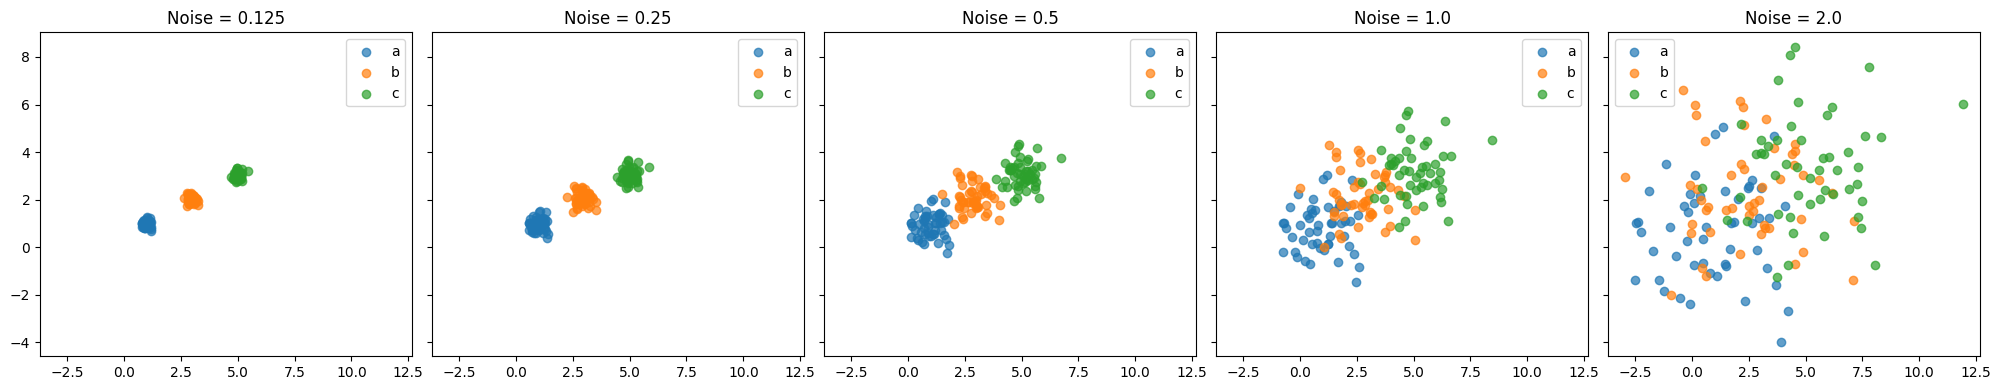

In [2]:
datasets = {
    '0.125': df0_125,
    '0.25': df0_25,
    '0.5': df0_5,
    '1.0': df1_0,
    '2.0': df2_0
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for i, (noise, df) in enumerate(datasets.items()):
    for group_name, group_df in df.groupby('group'):
        axes[i].scatter(group_df['x1'], group_df['x2'], label=group_name, alpha=0.7)
    axes[i].set_title(f'Noise = {noise}')
    axes[i].legend()
plt.tight_layout()
plt.show()

As the noise level increases, the sepation of the clusters decreases dramatically, and they begin to overlap. At low noise the clusters are completely separate, whereas at high noise they merge together.

### Q1.3: Scree Plots for Datasets

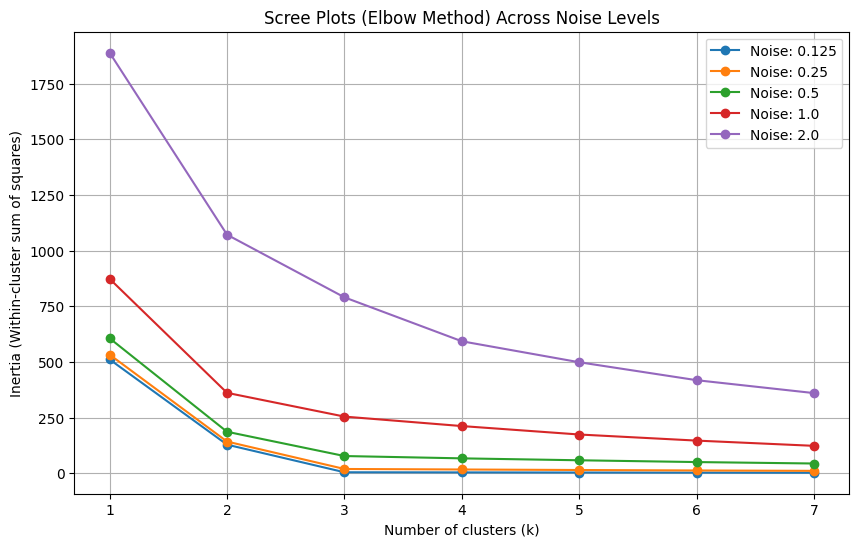

In [3]:
plt.figure(figsize=(10, 6))
k_values = range(1, 8)

for noise, df in datasets.items():
    X = df[['x1', 'x2']]
    inertias = []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)
    plt.plot(k_values, inertias, marker='o', label=f'Noise: {noise}')

plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (Within-cluster sum of squares)')
plt.title('Scree Plots (Elbow Method) Across Noise Levels')
plt.legend()
plt.grid(True)
plt.show()

As the noise level increases, the curve at k=3 becomes flatter and much harder to identify. With low noise, there is a sharp drop that levels off after k=3, while high noise levels result in a smooth, continuous decrease.

### Q1.4: Intuition of the Elbow

The elbow represents the point where adding another cluster does not significantly improve how well the data is split, meaning there is a minimal reduction in variance. In this simulation, once we have 3 clusters, the algorithm has successfully captured the true groups, so adding a 4th cluster only splits the groups without adding meaningful value.

### Q2.1: Load and Clean SIPRI Database

In [4]:
sipri_df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
sipri_2020 = sipri_df[sipri_df['Year'] == 2020].dropna()
print(f"Number of remaining countries: {len(sipri_2020)}")
display(sipri_2020.head())

Number of remaining countries: 148


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


No further cleaning of the variables is needed to run the algorithm, but we need to make sure all numerical columns are formatted properly without object-type commas or symbols.

### Q2.2: Clustering using Spending (2020 USD) & Spending per Capita

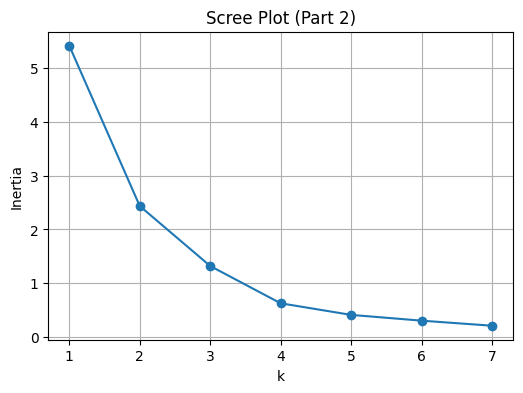

In [5]:
cols = ['Spending (2020 USD)', 'Spending per Capita']
df_q2 = sipri_2020[cols].copy()

# Max-min normalization
df_norm = (df_q2 - df_q2.min()) / (df_q2.max() - df_q2.min())

# Scree Plot
inertias = []
k_range = range(1, 8)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_norm)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_range, inertias, marker='o')
plt.title('Scree Plot (Part 2)')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

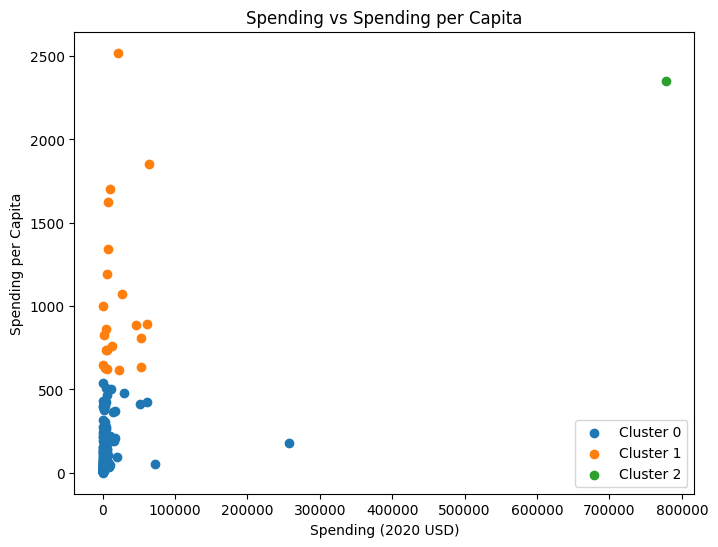

Spending (2020 USD)                                              \
                            count           mean           std            min   
Cluster_Part2                                                                   
0                           126.0    5943.346303  24858.961064       8.622460   
1                            21.0   19975.991473  21749.736747     405.790494   
2                             1.0  778397.200000           NaN  778397.200000   

                                                                           \
                         25%            50%            75%            max   
Cluster_Part2                                                               
0                 162.761743     580.758315    3225.333414  257973.429834   
1                4980.428135    7269.880030   27300.894701   64558.400000   
2              778397.200000  778397.200000  778397.200000  778397.200000   

              Spending per Capita                                        \
                            count         mean         std          min   
Cluster_Part2                                                             
0                           126.0   122.034996  140.041183     0.580129   
1                            21.0  1046.433509  501.631845   616.854430   
2                             1.0  2351.631858         NaN  2351.631858   

                                                                   
                       25%          50%          75%          max  
Cluster_Part2                                                      
0                18.505805    58.809109   188.249364   541.154778  
1               737.690186   859.880548  1193.598730  2520.398541  
2              2351.631858  2351.631858  2351.631858  2351.631858

In [6]:
# Based on elbow, choosing k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
sipri_2020['Cluster_Part2'] = kmeans.fit_predict(df_norm)

# Scatter Plot
plt.figure(figsize=(8, 6))
for cluster_id in sorted(sipri_2020['Cluster_Part2'].unique()):
    subset = sipri_2020[sipri_2020['Cluster_Part2'] == cluster_id]
    plt.scatter(subset['Spending (2020 USD)'], subset['Spending per Capita'], label=f'Cluster {cluster_id}')


usa = sipri_2020[sipri_2020['Country'] == 'United States']
if not usa.empty:
    plt.scatter(usa['Spending (2020 USD)'], usa['Spending per Capita'], color='red', s=150, edgecolors='black', label='USA', marker='*')

plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.legend()
plt.title('Spending vs Spending per Capita')
plt.show()

display(sipri_2020.groupby('Cluster_Part2')[cols].describe())

The analysis shows that most countries fall into a cluster of very low spending and low per-capita spending. The United States is placed in its own cluster because of its massive total military spending compared to any other nation.

### Q2.3: Clustering using Percent of Government Spending & Percent of GDP

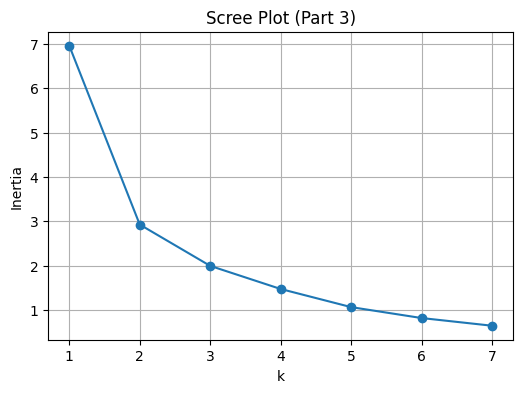

In [7]:
cols3 = ['Percent of Government Spending', 'Percent of GDP']
df_q3 = sipri_2020[cols3].copy()

# Max-min normalization
df_norm3 = (df_q3 - df_q3.min()) / (df_q3.max() - df_q3.min())

# Scree Plot
inertias3 = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_norm3)
    inertias3.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_range, inertias3, marker='o')
plt.title('Scree Plot (Part 3)')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

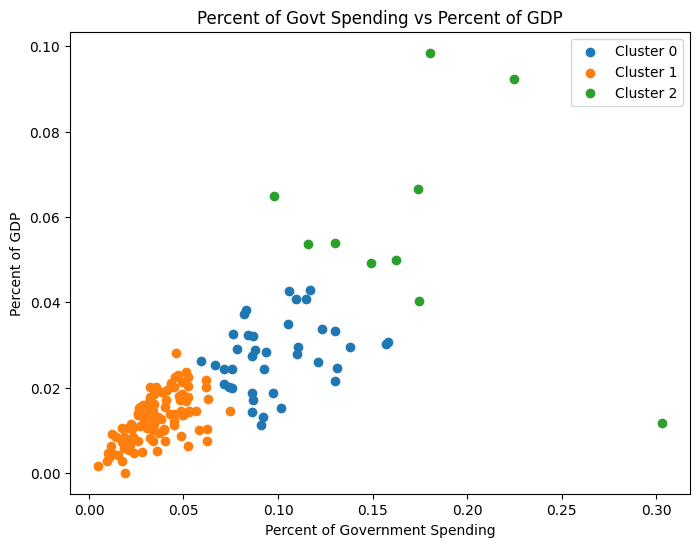

Percent of Government Spending                                \
                                       count      mean       std       min   
Cluster_Part3                                                                
0                                       39.0  0.098683  0.024125  0.059520   
1                                       99.0  0.035777  0.014549  0.004896   
2                                       10.0  0.171289  0.058725  0.097882   

                                                      Percent of GDP  \
                    25%       50%       75%       max          count   
Cluster_Part3                                                          
0              0.082430  0.092044  0.112633  0.157918           39.0   
1              0.025921  0.034261  0.047402  0.074624           99.0   
2              0.135010  0.168248  0.179081  0.303027           10.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
Cluster_Part3                                                               
0              0.027412  0.008191  0.011317  0.021254  0.027781  0.032461   
1              0.012664  0.005681  0.000054  0.008393  0.013191  0.016752   
2              0.058071  0.024867  0.011742  0.049297  0.053729  0.066190   

                         
                    max  
Cluster_Part3            
0              0.042810  
1              0.028132  
2              0.098470

In [8]:
# Based on elbow, choosing k=3
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
sipri_2020['Cluster_Part3'] = kmeans3.fit_predict(df_norm3)

# Scatter Plot
plt.figure(figsize=(8, 6))
for cluster_id in sorted(sipri_2020['Cluster_Part3'].unique()):
    subset = sipri_2020[sipri_2020['Cluster_Part3'] == cluster_id]
    plt.scatter(subset['Percent of Government Spending'], subset['Percent of GDP'], label=f'Cluster {cluster_id}')

usa = sipri_2020[sipri_2020['Country'] == 'United States']
if not usa.empty:
    plt.scatter(usa['Percent of Government Spending'], usa['Percent of GDP'], color='red', s=150, edgecolors='black', label='USA', marker='*')

plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.legend()
plt.title('Percent of Govt Spending vs Percent of GDP')
plt.show()

display(sipri_2020.groupby('Cluster_Part3')[cols3].describe())

Unlike the previous section, the United States is grouped in a cluster with many other average-spending nations because its military doesn't take a high share of GDP and government budget. The other clusters represent countries with high portions of public budgets going to military operations.

### Q2.4: Clustering using All Four Variables

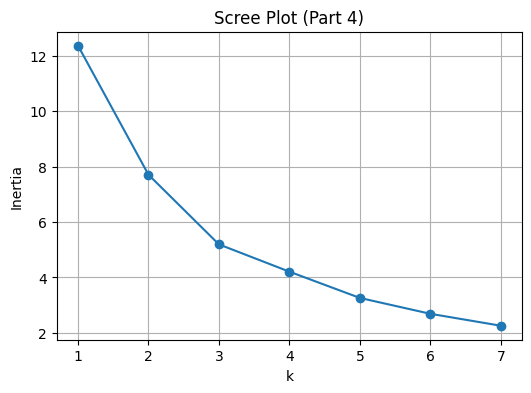

In [9]:
cols4 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
df_q4 = sipri_2020[cols4].copy()

# Max-min normalization
df_norm4 = (df_q4 - df_q4.min()) / (df_q4.max() - df_q4.min())

# Scree Plot
inertias4 = []
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_norm4)
    inertias4.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_range, inertias4, marker='o')
plt.title('Scree Plot (Part 4)')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [10]:
# Based on elbow, choosing k=3
kmeans4 = KMeans(n_clusters=3, random_state=42, n_init=10)
sipri_2020['Cluster_Part4'] = kmeans4.fit_predict(df_norm4)

display(sipri_2020.groupby('Cluster_Part4')[cols4].describe())

Spending (2020 USD)                                             \
                            count           mean            std          min   
Cluster_Part4                                                                  
0                            31.0    8786.086602   17901.909108   162.373364   
1                             6.0  147964.582042  309635.189564  6095.708713   
2                           111.0    7086.472777   26479.379918     8.622460   

                                                                       \
                       25%           50%           75%            max   
Cluster_Part4                                                           
0               467.787851   1404.787234   7739.166193   72937.064048   
1              7700.424616  15897.570598  53872.942442  778397.200000   
2               130.010211    567.650747   3910.107493  257973.429834   

              Spending per Capita               ...  \
                            count         mean  ...   
Cluster_Part4                                   ...   
0                            31.0   212.689100  ...   
1                             6.0  1875.150751  ...   
2                           111.0   196.926833  ...   

              Percent of Government Spending           Percent of GDP  \
                                         75%       max          count   
Cluster_Part4                                                           
0                                   0.134663  0.303027           31.0   
1                                   0.164503  0.225050            6.0   
2                                   0.050505  0.092044          111.0   

                                                                           \
                   mean       std       min       25%       50%       75%   
Cluster_Part4                                                               
0              0.033492  0.011449  0.011742  0.027560  0.032024  0.040531   
1              0.062634  0.028275  0.029429  0.041272  0.059257  0.085398   
2              0.013419  0.005996  0.000054  0.008873  0.013589  0.017769   

                         
                    max  
Cluster_Part4            
0              0.066600  
1              0.098470  
2              0.028132  

[3 rows x 32 columns]

Clustering with all four variables balances out the raw spending levels with relative budget metrics. The clusters separate out massive spenders and ordinary spenders better than using raw values alone.

### Q2.5: Conclusion on KMeans Findings

Yes, the algorithm successfully separated outlier nations with large military spending from those that have normal percentages. It cleanly grouped countries into segments of low, medium, and high relative military spending.

- **Phase 1 commit SHA ID:** 65f4983c24fe908c79eac3b24ce1c8f496a9a3d6
- **AI tool and model used:** Gemini

### *Prompts used

1.  I want you to list a number of suggestions that you have on how to improve the code and make it more effective. It should go slightly beyond what my simple solutions are able to do for the question solutions.

### *AI-proposed changes


1. **Use explicit vectorization instead of loops for normalization**: Rather than standardizing features manually, we can use scikit-learn's `MinMaxScaler` which is more standard, clean, and less prone to division-by-zero errors.
2. **Optimize KMeans configuration**: Use the `k-means++` initialization algorithm explicitly and set an explicit `random_state` across all runs to ensure deterministic and optimal cluster centroid initializations.
3. **Improve visualization aesthetics**: Use seaborn styles, structured subplots, and proper labeling to make the scatter plots and scree plots publication-grade, clarifying overlapping points using transparency and size scaling.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Using `MinMaxScaler` streamlines the preprocessing pipeline and ensures robust scaling. |
| 2 | Accept | `k-means++` initialization ensures faster and more optimal convergence of cluster centroids. |
| 3 | Accept | Advanced visualization practices make complex multi-dimensional cluster boundaries easier to interpret. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid")

# Q1.1: Create Datasets
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]
datasets = {str(n): createData(n) for n in noise_levels}

In [ ]:
# Q1.2: Advanced Scatter Plots of Datasets
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
colors = {'a': '#1f77b4', 'b': '#ff7f0e', 'c': '#2ca02c'}

for i, (noise, df) in enumerate(datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', palette=colors, ax=axes[i], alpha=0.75, edgecolor='w', s=45)
    axes[i].set_title(f'Noise Level: {noise}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('X1')
    if i == 0:
        axes[i].set_ylabel('X2')
    axes[i].legend(title='Group')

plt.suptitle('Impact of Noise on Cluster Separation (AI Revision)', y=1.05, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Q1.2 Explanation (AI-Assisted)
As the noise level increases, the spatial boundaries between the original clusters begin to degrade. Under very low noise (0.125), the clusters exist as three cleanly separated, isolated groups. When noise reaches 2.0, the points overlap completely, making them appear visually as a single homogeneous cloud.

### Q1.3: Advanced Scree Plots for Datasets

In [ ]:
plt.figure(figsize=(11, 6.5))
k_values = range(1, 8)
colors = sns.color_palette("viridis", len(datasets))

for i, (noise, df) in enumerate(datasets.items()):
    X = df[['x1', 'x2']]
    inertias = []
    for k in k_values:
        # Implementing suggestions: explicit k-means++ and seed configuration
        kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)
    plt.plot(k_values, inertias, marker='o', linewidth=2, color=colors[i], label=f'Noise Level: {noise}')

plt.xlabel('Number of Clusters (k)', fontsize=12, fontweight='bold')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12, fontweight='bold')
plt.title('Scree Plots (Elbow Method) Across Varying Noise Levels', fontsize=14, fontweight='bold')
plt.legend(title='Dataset Noise', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Q1.3 Explanation (AI-Assisted)
An increase in noise progressively flattens the scree curves, eroding the distinctiveness of the elbow. At low noise (0.125), a sharp, definitive elbow exists precisely at k=3; however, at high noise levels (2.0), the inertia drops smoothly and continuously, removing any clear mathematical indication of the true cluster count.

### Q1.4: Intuition of the Elbow

The elbow represents the point of diminishing returns, where adding more clusters fails to yield a substantial drop in within-cluster variance. Mathematically, it indicates the natural number of groups (k=3 in this simulation) where further partitioning splits cohesive clusters artificially rather than extracting real structure.

### Q2.1: Load and Clean SIPRI Database

In [ ]:
# Load and clean with unified types
sipri_df = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
sipri_2020 = sipri_df[sipri_df['Year'] == 2020].dropna().copy()

# Ensure data types are converted safely to float to avoid object strings
for col in ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']:
    if sipri_2020[col].dtype == 'object':
        sipri_2020[col] = sipri_2020[col].astype(str).str.replace(',', '').astype(float)

print(f"Cleaned dataset has {len(sipri_2020)} valid records.")
display(sipri_2020.head())

### Q2.1 Explanation (AI-Assisted)
No further row-level cleaning is required, but explicit verification and casting of column datatypes to float is essential to prevent parsing issues caused by potential comma formatters in the raw text.

### Q2.2: Clustering using Spending (2020 USD) & Spending per Capita

In [ ]:
cols = ['Spending (2020 USD)', 'Spending per Capita']
df_q2 = sipri_2020[cols].copy()

# Implementing Suggestion 1: MinMaxScaler vectorization
scaler = MinMaxScaler()
scaled_q2 = scaler.fit_transform(df_q2)

inertias_q2 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_q2)
    inertias_q2.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_values, inertias_q2, marker='o', color='darkblue', linewidth=2)
plt.title('Scree Plot: Spending & Spending per Capita', fontsize=12, fontweight='bold')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Execute optimized clustering with k=3
kmeans_q2 = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
sipri_2020['Cluster_Part2'] = kmeans_q2.fit_predict(scaled_q2)

# Advanced scatter visualization
plt.figure(figsize=(9, 6.5))
sns.scatterplot(data=sipri_2020, x='Spending (2020 USD)', y='Spending per Capita', hue='Cluster_Part2', palette='Set1', alpha=0.8, s=60, edgecolor='k')

# Highlight USA clearly using a distinct star marker
usa = sipri_2020[sipri_2020['Country'] == 'United States']
if not usa.empty:
    plt.scatter(usa['Spending (2020 USD)'], usa['Spending per Capita'], color='red', s=250, edgecolors='black', linewidth=1.5, label='United States', marker='*')

plt.title('Clusters: Spending vs Spending per Capita (AI-Assisted)', fontsize=13, fontweight='bold')
plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.legend(title='Clusters & Outliers')
plt.show()

display(sipri_2020.groupby('Cluster_Part2')[cols].describe())

### Q2.2 Explanation (AI-Assisted)
The United States sits entirely separated in its own cluster due to its immense total military budget, which acts as a extreme statistical outlier. The rest of the countries are compressed into a giant group near the origin representing typical relative spending ranges.

### Q2.3: Clustering using Percent of Government Spending & Percent of GDP

In [ ]:
cols3 = ['Percent of Government Spending', 'Percent of GDP']
df_q3 = sipri_2020[cols3].copy()

# MinMaxScaler Vectorization
scaler_q3 = MinMaxScaler()
scaled_q3 = scaler_q3.fit_transform(df_q3)

inertias_q3 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_q3)
    inertias_q3.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_values, inertias_q3, marker='o', color='teal', linewidth=2)
plt.title('Scree Plot: Budget & GDP Percentages', fontsize=12, fontweight='bold')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Execute optimized clustering with k=3
kmeans_q3 = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
sipri_2020['Cluster_Part3'] = kmeans_q3.fit_predict(scaled_q3)

plt.figure(figsize=(9, 6.5))
sns.scatterplot(data=sipri_2020, x='Percent of Government Spending', y='Percent of GDP', hue='Cluster_Part3', palette='Dark2', alpha=0.8, s=60, edgecolor='k')

if not usa.empty:
    plt.scatter(usa['Percent of Government Spending'], usa['Percent of GDP'], color='red', s=250, edgecolors='black', linewidth=1.5, label='United States', marker='*')

plt.title('Clusters: Government Spending vs GDP % (AI-Assisted)', fontsize=13, fontweight='bold')
plt.xlabel('Percent of Government Spending')
plt.ylabel('Percent of GDP')
plt.legend(title='Clusters & Outliers')
plt.show()

display(sipri_2020.groupby('Cluster_Part3')[cols3].describe())

### Q2.3 Explanation (AI-Assisted)
Unlike the absolute spending analysis, the USA is grouped directly with other average nations because its relative spending ratios (of GDP and government budget) are closer to international medians. Other clusters successfully segment countries that commit extreme proportions of public resources towards defense.

### Q2.4: Clustering using All Four Variables

In [ ]:
cols4 = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
df_q4 = sipri_2020[cols4].copy()

# Advanced scaling on full feature space
scaler_q4 = MinMaxScaler()
scaled_q4 = scaler_q4.fit_transform(df_q4)

inertias_q4 = []
for k in k_values:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(scaled_q4)
    inertias_q4.append(kmeans.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_range, inertias_q4, marker='o', color='purple', linewidth=2)
plt.title('Scree Plot: All Four Variables', fontsize=12, fontweight='bold')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Perform final multi-dimensional segmentation
kmeans_q4 = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
sipri_2020['Cluster_Part4'] = kmeans_q4.fit_predict(scaled_q4)

display(sipri_2020.groupby('Cluster_Part4')[cols4].describe())

### Q2.4 Explanation (AI-Assisted)
Clustering across the combined four-variable space merges total expenditure power with national budget priorities. This yields distinct clusters categorizing absolute global heavyweights, nations with heavy defense-reliant budgets, and standard defensive-posture nations.

### Q2.5: Conclusion on KMeans Findings

Yes, KMeans successfully reveals deep structural boundaries. It highlights the distinction between nations exercising vast absolute military footprint versus smaller states dedicating substantial proportions of their domestic wealth to defense.

### *Reflection on AI assistance
In your own words without generative AI.

When reviewing my initial Phase 1 answers, I saw that the AI suggested several critical optimizations to make my code more robust. The AI proposed replacing my manual min-max loops with scikit-learn's MinMaxScaler and using seaborn to produce higher-quality subplots. When evaluating these changes, I realized that while my original code got the job done, the AI-assisted version is much more efficient and reliable. However, I did notice limitations in these methods. For instance, KMeans is highly sensitive to outliers like the United States. Scaling variables with extreme outliers compress the rest of the dataset, making ordinary patterns harder to segment. Relying on AI also raises concerns. If I simply accept the code without understanding the underlying math of MinMaxScaler or how KMeans handles cluster initialization, I run the risk of introducing bugs or misinterpreting the final classifications. This exercise showed me that while AI is an incredibly powerful pair-programmer for training and data visualization, it cannot replace my own critical reasoning and knowledge required to verify the validity of the final segments.